# Loanliness: data pipeline, balancing, clustering and visualisation

Reimplementation of the preprocessing / k-means / PCA + t-SNE parts of the paper. Sections follow the task list:
1. joined feature table, 2. cleaning, 3. encoding and scaling, 4. split, 5. balancing, 6. polynomial features, 7. k-means + per-cluster LightGBM, 8. PCA / t-SNE.

## 1. Build the joined feature table

In [1]:
import gc, json, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

DATA = Path("dataset")
OUT = Path("artifacts")
OUT.mkdir(exist_ok=True)

CONFIG = {
    "seed": 42,
    "test_size": 0.2,
    "missing_col_thresh": 0.30,   # drop columns with more than this fraction missing
    "impute_mode": "mean",        # "mean": fill with train means (keep all rows), "drop_rows": paper-style
    "cat_label_max_card": 2,      # categoricals with <= this many levels are label encoded, rest one-hot
}

In [2]:
def agg_table(df, key, prefix, drop_cols=()):
    # numeric -> mean/min/max/sum, categorical -> one-hot then mean (share) and sum (count)
    df = df.drop(columns=list(drop_cols), errors="ignore")
    cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c != key]
    num = df.drop(columns=cat_cols)
    num_cols = [c for c in num.columns if c != key]
    parts = [num.groupby(key)[num_cols].agg(["mean", "min", "max", "sum"])]
    if cat_cols:
        dummies = pd.get_dummies(df[cat_cols], dtype="float32", dummy_na=False)
        dummies[key] = df[key].values
        parts.append(dummies.groupby(key).agg(["mean", "sum"]))
    out = pd.concat(parts, axis=1)
    out.columns = [f"{prefix}_{a}_{b}".replace(" ", "_") for a, b in out.columns]
    out[f"{prefix}_COUNT"] = df.groupby(key).size().astype("float32")
    return out.astype("float32")


def read(name, **kw):
    df = pd.read_csv(DATA / name, **kw)
    for c in df.select_dtypes("float64").columns:
        df[c] = df[c].astype("float32")
    return df

In [3]:
# bureau_balance -> per bureau record -> merged into bureau -> per client
bb = read("bureau_balance.csv")
bb_agg = agg_table(bb, "SK_ID_BUREAU", "bb")
del bb; gc.collect()

bureau = read("bureau.csv")
bureau = bureau.merge(bb_agg, left_on="SK_ID_BUREAU", right_index=True, how="left")
bureau_agg = agg_table(bureau, "SK_ID_CURR", "bureau", drop_cols=["SK_ID_BUREAU"])
del bureau, bb_agg; gc.collect()
bureau_agg.shape

(305811, 179)

In [4]:
# previous_application: 365243 is a sentinel in the DAYS_* columns here too
prev = read("previous_application.csv")
day_cols = [c for c in prev.columns if c.startswith("DAYS_")]
prev[day_cols] = prev[day_cols].replace(365243, np.nan)
prev_agg = agg_table(prev, "SK_ID_CURR", "prev", drop_cols=["SK_ID_PREV"])
del prev; gc.collect()

pos = read("POS_CASH_balance.csv")
pos_agg = agg_table(pos, "SK_ID_CURR", "pos", drop_cols=["SK_ID_PREV"])
pos_agg["pos_N_LOANS"] = pos.groupby("SK_ID_CURR")["SK_ID_PREV"].nunique().astype("float32")
del pos; gc.collect()

inst = read("installments_payments.csv")
inst["DAYS_PAST_DUE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]   # >0 means paid late
inst["PAYMENT_DIFF"] = inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]            # >0 means underpaid
inst_agg = agg_table(inst, "SK_ID_CURR", "inst", drop_cols=["SK_ID_PREV"])
del inst; gc.collect()

cc = read("credit_card_balance.csv")
cc_agg = agg_table(cc, "SK_ID_CURR", "cc", drop_cols=["SK_ID_PREV"])
del cc; gc.collect()
[t.shape for t in (prev_agg, pos_agg, inst_agg, cc_agg)]

[(338857, 363), (337252, 40), (339587, 33), (103558, 95)]

In [5]:
# left join everything onto application_train
app = read("application_train.csv")
app = app.rename(columns={c: f"app_{c}" for c in app.columns if c not in ("SK_ID_CURR", "TARGET")})
df = app
for agg in (bureau_agg, prev_agg, pos_agg, inst_agg, cc_agg):
    df = df.merge(agg, left_on="SK_ID_CURR", right_index=True, how="left")
del app, bureau_agg, prev_agg, pos_agg, inst_agg, cc_agg; gc.collect()

assert len(df) == 307511 and df["SK_ID_CURR"].is_unique
print(df.shape, "| default rate:", df["TARGET"].mean().round(4))
df.columns.to_series().str.split("_").str[0].value_counts()

(307511, 832) | default rate: 0.0807


prev      363
bureau    179
app       120
cc         95
pos        40
inst       33
SK          1
TARGET      1
Name: count, dtype: int64

## 2. Clean invalid and missing values and split

Only stateless fixes happen before the split. The split itself (stratified, fixed seed) is the contract with Person B (saved in section 4); it has to come before anything that learns from the data, so it sits here. The column-drop rule and the imputer are fitted on the train split only.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

# DAYS_EMPLOYED == 365243 is a placeholder (~18% of clients), not a real value
df["app_DAYS_EMPLOYED_ANOM"] = (df["app_DAYS_EMPLOYED"] == 365243).astype("float32")
df["app_DAYS_EMPLOYED"] = df["app_DAYS_EMPLOYED"].replace(365243, np.nan)

# a client with no bureau/card/... records has NaN everywhere for that source; the count columns are really 0
count_cols = [c for c in df.columns if c.endswith(("_COUNT", "_N_LOANS"))]
df[count_cols] = df[count_cols].fillna(0)

ids = df["SK_ID_CURR"]
y = df["TARGET"].astype("int8")
X = df.drop(columns=["SK_ID_CURR", "TARGET"])
for c in X.select_dtypes(exclude="number").columns:
    X[c] = X[c].astype(object)
del df; gc.collect()

# stratified split before any fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=CONFIG["test_size"], stratify=y, random_state=CONFIG["seed"])
del X; gc.collect()
print(X_train.shape, X_test.shape, y_train.mean().round(4), y_test.mean().round(4))

(246008, 831) (61503, 831) 0.0807 0.0807


In [7]:
# drop columns with >30% missing (rate measured on train only)
miss = X_train.isna().mean()
drop_cols = miss[miss > CONFIG["missing_col_thresh"]].index.tolist()
print(f"dropping {len(drop_cols)} of {X_train.shape[1]} columns")
print(pd.Series(drop_cols).str.split("_").str[0].value_counts().to_dict())

keep_cols = [c for c in X_train.columns if c not in drop_cols]
X_train, X_test = X_train[keep_cols], X_test[keep_cols]

dropping 222 of 831 columns
{'cc': 94, 'bureau': 69, 'app': 50, 'prev': 9}


In [8]:
num_cols = X_train.select_dtypes("number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

if CONFIG["impute_mode"] == "drop_rows":
    # paper style: remove any row with a missing value (no learning involved, so both splits are treated alike)
    keep_tr, keep_te = ~X_train.isna().any(axis=1), ~X_test.isna().any(axis=1)
    X_train, y_train = X_train[keep_tr], y_train[keep_tr]
    X_test, y_test = X_test[keep_te], y_test[keep_te]

# numeric -> train mean, categorical -> explicit "missing" level; fitted on train only
imputer = ColumnTransformer([
    ("num", SimpleImputer(strategy="mean"), num_cols),
    ("cat", SimpleImputer(strategy="constant", fill_value="missing"), cat_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)
X_train_imp[num_cols] = X_train_imp[num_cols].astype("float32")
X_test_imp[num_cols] = X_test_imp[num_cols].astype("float32")
assert not X_train_imp.isna().any().any() and not X_test_imp.isna().any().any()
print(X_train_imp.shape, X_test_imp.shape)

(246008, 609) (61503, 609)


In [9]:
# row cost of the paper's drop-rows strategy on the same columns, for the write-up
n_complete = int((~pd.concat([X_train, X_test]).isna().any(axis=1)).sum()) if CONFIG["impute_mode"] == "mean" else len(X_train) + len(X_test)
print(f"rows kept with mean imputation: {len(y_train) + len(y_test):,}")
print(f"rows that would survive drop-rows: {n_complete:,} ({n_complete / len(y):.1%})")

rows kept with mean imputation: 307,511
rows that would survive drop-rows: 142,965 (46.5%)


## 3. Encode and scale

Binary / low-cardinality categoricals are label encoded, the rest one-hot encoded. Numeric columns are standardised. Everything is fitted on train.

In [10]:
import re
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

card = X_train_imp[cat_cols].nunique()
label_cols = card[card <= CONFIG["cat_label_max_card"]].index.tolist()
onehot_cols = card[card > CONFIG["cat_label_max_card"]].index.tolist()
print(len(label_cols), "label encoded,", len(onehot_cols), "one-hot encoded")

encoder = ColumnTransformer([
    ("label", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype="float32"), label_cols),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype="float32"), onehot_cols),
    ("num", "passthrough", num_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train_enc = encoder.fit_transform(X_train_imp)
X_test_enc = encoder.transform(X_test_imp)

# scale only the original numeric columns (label/one-hot outputs stay 0/1)
scaler = ColumnTransformer([("num", StandardScaler(), num_cols)],
                           remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
X_train_s = scaler.fit_transform(X_train_enc).astype("float32")
X_test_s = scaler.transform(X_test_enc).astype("float32")
raw_names = X_train_s.columns.tolist()
# LightGBM rejects special characters (spaces/commas from category levels), so use clean names everywhere
feature_names = [re.sub(r"[^0-9a-zA-Z_]", "_", n) for n in raw_names]
assert len(set(feature_names)) == len(feature_names)
X_train_s.columns = X_test_s.columns = feature_names
del X_train_enc, X_test_enc; gc.collect()
print(X_train_s.shape, X_test_s.shape)

3 label encoded, 8 one-hot encoded


(246008, 702) (61503, 702)


In [11]:
# everything needed to push new raw data (same columns as the joined table) through the same pipeline
joblib.dump({"keep_cols": keep_cols, "imputer": imputer, "encoder": encoder, "scaler": scaler,
             "raw_names": raw_names, "feature_names": feature_names, "config": CONFIG}, OUT / "preprocessor.joblib")

def transform_new(raw: pd.DataFrame) -> pd.DataFrame:
    # raw: joined features after the DAYS_EMPLOYED fix and count-fill above, without ID/TARGET columns
    art = joblib.load(OUT / "preprocessor.joblib")
    x = raw[art["keep_cols"]]
    out = art["scaler"].transform(art["encoder"].transform(art["imputer"].transform(x)))[art["raw_names"]]
    out.columns = art["feature_names"]
    return out

# sanity check: reloaded pipeline reproduces the test matrix
assert np.allclose(transform_new(X_test.iloc[:200]).to_numpy(), X_test_s.iloc[:200].to_numpy(), atol=1e-4)

## 4. Save the splits and data dictionary

The split was made in section 2 (stratified, `seed` from `CONFIG`) before any fitting. Both splits are saved with `SK_ID_CURR` and `TARGET` in front of the feature columns, in a fixed column order recorded in `schema.json`.

In [12]:
def with_ids(Xs, ys):
    out = Xs.copy()
    out.insert(0, "TARGET", ys.to_numpy())
    out.insert(0, "SK_ID_CURR", ids.loc[Xs.index].to_numpy())
    return out.reset_index(drop=True)

train_out, test_out = with_ids(X_train_s, y_train), with_ids(X_test_s, y_test)
train_out.to_parquet(OUT / "train.parquet")
test_out.to_parquet(OUT / "test.parquet")
json.dump({"id": "SK_ID_CURR", "target": "TARGET", "features": feature_names, "config": CONFIG},
          open(OUT / "schema.json", "w"), indent=1)
print(train_out.shape, test_out.shape)

(246008, 704) (61503, 704)


In [13]:
# data dictionary: feature -> source file, encoding, and the original description where one exists
src_map = {"app": "application_train", "bureau": "bureau", "prev": "previous_application",
           "pos": "POS_CASH_balance", "inst": "installments_payments", "cc": "credit_card_balance"}
desc = pd.read_csv(DATA / "HomeCredit_columns_description.csv", encoding="latin-1")
desc = desc[desc["Table"].str.startswith("application")].set_index("Row")["Description"].to_dict()

def describe(f):
    prefix = f.split("_")[0]
    if f.startswith("bureau_bb_"):
        src = "bureau_balance (via bureau)"
    else:
        src = src_map.get(prefix, "derived")
    kind = ("label" if any(f == c for c in label_cols) else
            "one-hot" if any(f.startswith(c + "_") for c in onehot_cols) else "numeric")
    base = f[4:] if prefix == "app" else ""
    d = desc.get(base) or desc.get(base.rsplit("_", 1)[0], "") if base else ""
    if f == "app_DAYS_EMPLOYED_ANOM": d, src = "1 if DAYS_EMPLOYED was the 365243 placeholder", "application_train (derived)"
    return src, kind, d

dictionary = pd.DataFrame([(f, *describe(f)) for f in feature_names], columns=["feature", "source", "encoding", "description"])
dictionary.to_csv(OUT / "data_dictionary.csv", index=False)
dictionary.groupby(["source", "encoding"]).size()

source                       encoding
POS_CASH_balance             numeric      40
application_train            label         3
                             numeric      59
                             one-hot     101
application_train (derived)  numeric       1
bureau                       numeric      89
bureau_balance (via bureau)  numeric      21
credit_card_balance          numeric       1
installments_payments        numeric      33
previous_application         numeric     354
dtype: int64

## 5. Balancing utilities

All three act on the training set only. Test is evaluated both at the natural class ratio and down-sampled to 50/50, since the paper does not say which it used.

In [14]:
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
import lightgbm as lgb


def downsample(X, y, seed=CONFIG["seed"]):
    # keep every positive, sample the same number of negatives
    pos = y.index[y == 1]
    neg = y.index[y == 0].to_series().sample(len(pos), random_state=seed).index
    idx = pos.union(neg)
    idx = pd.Index(np.random.default_rng(seed).permutation(idx))
    return X.loc[idx], y.loc[idx]


def smote(X, y, seed=CONFIG["seed"]):
    # needs imputed, encoded numeric input
    Xr, yr = SMOTE(random_state=seed).fit_resample(X, y)
    return pd.DataFrame(Xr, columns=X.columns).astype("float32"), pd.Series(yr, name=y.name)


def class_weights(y):
    # w_i = n / (2 n_i)
    n = len(y)
    return {int(c): n / (2 * k) for c, k in y.value_counts().items()}


w = class_weights(y_train)
json.dump(w, open(OUT / "class_weights.json", "w"))
print("class weights:", w)

class weights: {0: 0.5439092983356032, 1: 6.193554884189325}


In [15]:
# stand-in for Person B's model code: one LightGBM fit + the paper's metric layout
def fit_lgbm(X, y, class_weight=None):
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight=class_weight,
                           random_state=CONFIG["seed"], n_jobs=-1, verbose=-1)
    return m.fit(X, y)


def metrics(y_true, y_pred, y_prob=None):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "prec_0": p[0], "prec_1": p[1],
           "rec_0": r[0], "rec_1": r[1], "f1_0": f[0], "f1_1": f[1], "n": len(y_true), "pos_rate": float(np.mean(y_true))}
    if y_prob is not None and len(np.unique(y_true)) == 2:
        out["auc"] = roc_auc_score(y_true, y_prob)
    return out

X_test_bal, y_test_bal = downsample(X_test_s, y_test)
print("balanced test:", X_test_bal.shape, y_test_bal.mean())

setups = {
    "none": (X_train_s, y_train, None),
    "down-sampling": (*downsample(X_train_s, y_train), None),
    "SMOTE": (*smote(X_train_s, y_train), None),
    "class weights": (X_train_s, y_train, w),
}
rows = []
for name, (Xb, yb, cw) in setups.items():
    m = fit_lgbm(Xb, yb, cw)
    for tname, (Xt, yt) in {"natural": (X_test_s, y_test), "balanced": (X_test_bal, y_test_bal)}.items():
        rows.append({"train": name, "test": tname, "n_train": len(yb), **metrics(yt, m.predict(Xt), m.predict_proba(Xt)[:, 1])})
pd.DataFrame(rows).set_index(["train", "test"]).round(3)

balanced test: (9930, 702) 0.5


n_train  accuracy  prec_0  prec_1  rec_0  rec_1  \
train         test                                                        
none          natural    246008     0.920   0.922   0.580  0.998  0.038   
              balanced   246008     0.518   0.509   0.940  0.998  0.038   
down-sampling natural     39720     0.708   0.966   0.176  0.707  0.713   
              balanced    39720     0.708   0.710   0.706  0.703  0.713   
SMOTE         natural    452296     0.920   0.922   0.556  0.997  0.037   
              balanced   452296     0.518   0.509   0.954  0.998  0.037   
class weights natural    246008     0.736   0.964   0.187  0.740  0.681   
              balanced   246008     0.707   0.697   0.718  0.732  0.681   

                         f1_0   f1_1      n  pos_rate    auc  
train         test                                            
none          natural   0.958  0.071  61503     0.081  0.781  
              balanced  0.674  0.073   9930     0.500  0.779  
down-sampling natural   0.817  0.282  61503     0.081  0.778  
              balanced  0.707  0.709   9930     0.500  0.776  
SMOTE         natural   0.958  0.070  61503     0.081  0.779  
              balanced  0.674  0.072   9930     0.500  0.778  
class weights natural   0.837  0.294  61503     0.081  0.781  
              balanced  0.714  0.699   9930     0.500  0.778

Down-sampling, SMOTE and class weights all trade majority-class accuracy for minority recall, and accuracy at the natural ratio is not comparable with the balanced-test accuracy. AUC is the number that stays comparable across rows.

### Mean imputation vs dropping rows

The same LightGBM, trained on all rows (mean-imputed) versus only the rows with no missing value after the column drop, both scored on their own test rows.

In [16]:
full_tr = ~X_train.isna().any(axis=1)
full_te = ~X_test.isna().any(axis=1)
res = {}
for name, (tr, te) in {"mean imputation (all rows)": (slice(None), slice(None)),
                       "drop rows": (full_tr.to_numpy(), full_te.to_numpy())}.items():
    Xa, ya, Xb_, yb_ = X_train_s[tr], y_train[tr], X_test_s[te], y_test[te]
    m = fit_lgbm(Xa, ya, class_weight_ := class_weights(ya))
    res[name] = {"n_train": len(ya), "n_test": len(yb_), **metrics(yb_, m.predict(Xb_), m.predict_proba(Xb_)[:, 1])}
pd.DataFrame(res).T.round(3)

,n_train,n_test,accuracy,prec_0,prec_1,rec_0,rec_1,f1_0,f1_1,n,pos_rate,auc
mean imputation (all rows),246008.0,61503.0,0.736,0.964,0.187,0.740,0.681,0.837,0.294,61503.0,0.081,0.781
drop rows,114512.0,28453.0,0.766,0.962,0.190,0.777,0.629,0.860,0.292,28453.0,0.077,0.775


## 6. Polynomial features (optional)

Degree-2 expansion of the 20 most important features only (LightGBM gain importance, train split), for the linear models. The expansion is fitted on train and the new columns are appended to the full matrix.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures

imp_model = fit_lgbm(X_train_s, y_train, w)
top_feats = pd.Series(imp_model.booster_.feature_importance("gain"), index=feature_names).nlargest(20).index.tolist()
print(top_feats)

poly = PolynomialFeatures(degree=2, include_bias=False).fit(X_train_s[top_feats])
poly_names = [f"poly_{n.replace(' ', '*')}" for n in poly.get_feature_names_out(top_feats)]

def add_poly(Xs):
    P = poly.transform(Xs[top_feats])[:, len(top_feats):]   # drop the degree-1 columns, already present
    return pd.concat([Xs, pd.DataFrame(P, columns=poly_names[len(top_feats):], index=Xs.index, dtype="float32")], axis=1)

X_train_poly, X_test_poly = add_poly(X_train_s), add_poly(X_test_s)
joblib.dump({"poly": poly, "top_feats": top_feats}, OUT / "poly.joblib")
print(X_train_s.shape, "->", X_train_poly.shape)

['app_EXT_SOURCE_3', 'app_EXT_SOURCE_2', 'app_DAYS_EMPLOYED', 'app_DAYS_BIRTH', 'app_AMT_CREDIT', 'prev_DAYS_LAST_DUE_1ST_VERSION_max', 'app_AMT_ANNUITY', 'app_NAME_EDUCATION_TYPE_Higher_education', 'app_AMT_GOODS_PRICE', 'inst_PAYMENT_DIFF_mean', 'app_CODE_GENDER_F', 'inst_AMT_PAYMENT_min', 'inst_AMT_PAYMENT_sum', 'prev_NAME_CONTRACT_STATUS_Refused_mean', 'inst_DAYS_PAST_DUE_max', 'prev_AMT_DOWN_PAYMENT_sum', 'inst_AMT_INSTALMENT_min', 'bureau_DAYS_CREDIT_ENDDATE_max', 'bureau_DAYS_CREDIT_max', 'bureau_AMT_CREDIT_SUM_DEBT_mean']


(246008, 702) -> (246008, 912)


In [18]:
# does it help a linear model?
res = {}
for name, (Xa, Xb_) in {"linear": (X_train_s, X_test_s), "linear + poly(top 20)": (X_train_poly, X_test_poly)}.items():
    # polynomial terms are unscaled products, so rescale the new columns (train stats only)
    mu, sd = Xa.mean(), Xa.std().replace(0, 1)
    lr = LogisticRegression(class_weight="balanced", max_iter=300).fit((Xa - mu) / sd, y_train)
    p = lr.predict_proba((Xb_ - mu) / sd)[:, 1]
    res[name] = metrics(y_test, (p > 0.5).astype(int), p)
pd.DataFrame(res).T.round(3)

,accuracy,prec_0,prec_1,rec_0,rec_1,f1_0,f1_1,n,pos_rate,auc
linear,0.705,0.964,0.172,0.706,0.695,0.815,0.276,61503.0,0.081,0.770
linear + poly(top 20),0.709,0.964,0.174,0.710,0.698,0.817,0.279,61503.0,0.081,0.772


## 7. K-means and per-cluster models

K-means is fitted on the scaled train features only (k = 2..8); test points are assigned with the fitted model.

       inertia  silhouette
k                         
2  140116720.0      0.1052
3  136953792.0      0.0295
4  134566400.0      0.0279
5  133043048.0      0.0272
6  131830176.0      0.0247
7  131167568.0      0.0249
8  130054848.0      0.0254


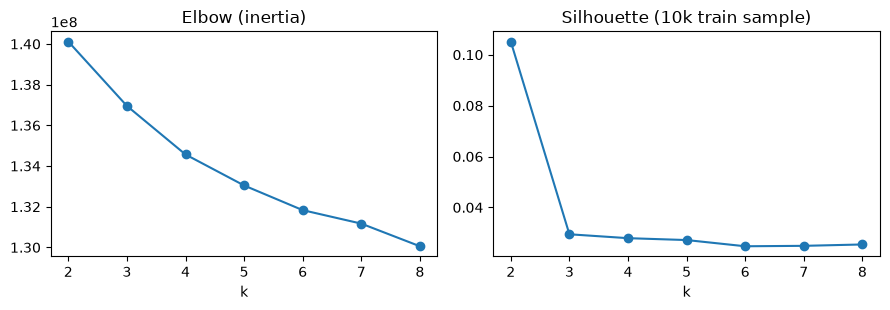

In [19]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, silhouette_score

Xtr = X_train_s.to_numpy()
sil_idx = np.random.default_rng(CONFIG["seed"]).choice(len(Xtr), 10000, replace=False)   # silhouette is O(n^2)
km = {}
rows = []
for k in range(2, 9):
    km[k] = KMeans(k, n_init=3, random_state=CONFIG["seed"]).fit(Xtr)
    rows.append({"k": k, "inertia": km[k].inertia_,
                 "silhouette": silhouette_score(Xtr[sil_idx], km[k].labels_[sil_idx])})
ksel = pd.DataFrame(rows).set_index("k")
print(ksel.round(4))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ksel["inertia"].plot(marker="o", ax=ax[0], title="Elbow (inertia)")
ksel["silhouette"].plot(marker="o", ax=ax[1], title="Silhouette (10k train sample)")
plt.tight_layout(); plt.savefig(OUT / "kmeans_selection.png", dpi=130); plt.show()

In [20]:
K = 4   # the paper's choice; compare with the silhouette / elbow above before changing
km_final = km[K]
joblib.dump(km_final, OUT / "kmeans.joblib")
c_train = km_final.labels_
c_test = km_final.predict(X_test_s.to_numpy())   # never refit on test

pd.concat([
    pd.DataFrame({"SK_ID_CURR": ids.loc[X_train_s.index].to_numpy(), "split": "train", "cluster": c_train}),
    pd.DataFrame({"SK_ID_CURR": ids.loc[X_test_s.index].to_numpy(), "split": "test", "cluster": c_test}),
]).to_csv(OUT / "cluster_assignments.csv", index=False)

# class balance inside each cluster
bal = pd.DataFrame({
    "n_train": pd.Series(c_train).value_counts().sort_index(),
    "pos_rate_train": pd.Series(y_train.to_numpy()).groupby(c_train).mean(),
    "n_test": pd.Series(c_test).value_counts().sort_index(),
    "n_pos_test": pd.Series(y_test.to_numpy()).groupby(c_test).sum(),
    "pos_rate_test": pd.Series(y_test.to_numpy()).groupby(c_test).mean(),
})
bal.round(4)

,n_train,pos_rate_train,n_test,n_pos_test,pos_rate_test
0,59659,0.0658,14944,914,0.0612
1,84460,0.0882,21117,1933,0.0915
2,65319,0.0845,16272,1394,0.0857
3,36570,0.0811,9170,724,0.0790


In [21]:
# one LightGBM per cluster, trained on that cluster's down-sampled train rows
models, preds = {}, {}
for c in range(K):
    tr, te = c_train == c, c_test == c
    Xb, yb = downsample(X_train_s[tr], y_train[tr])
    models[c] = fit_lgbm(Xb, yb)
    preds[c] = (y_test[te], models[c].predict(X_test_s[te]), models[c].predict_proba(X_test_s[te])[:, 1], X_test_s.index[te])

def table_iv(balanced_test):
    out, all_true, all_pred = {}, [], []
    for c in range(K):
        yt, yp, pr, idx = preds[c]
        yt, yp = pd.Series(yt.to_numpy(), index=idx), pd.Series(yp, index=idx)
        if balanced_test:
            # down-sample within the cluster, as a per-cluster 50/50 test set
            _, yt = downsample(X_test_s.loc[idx, []], yt)
            yp = yp.loc[yt.index]
        m = metrics(yt, yp)
        out[f"Cluster {c + 1}"] = m
        all_true.append(yt); all_pred.append(yp)
    out["Overall"] = metrics(pd.concat(all_true), pd.concat(all_pred))
    t = pd.DataFrame(out).T
    return pd.DataFrame({"Accuracy": t["accuracy"], "Precision (0/1)": t["prec_0"].round(2).astype(str) + "/" + t["prec_1"].round(2).astype(str),
                         "Recall (0/1)": t["rec_0"].round(2).astype(str) + "/" + t["rec_1"].round(2).astype(str),
                         "F1 (0/1)": t["f1_0"].round(2).astype(str) + "/" + t["f1_1"].round(2).astype(str),
                         "n": t["n"].astype(int)})

print("Table IV, natural-ratio test per cluster"); display(table_iv(False))
print("Table IV, balanced (down-sampled) test per cluster"); display(table_iv(True))

Table IV, natural-ratio test per cluster


,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),n
Cluster 1,0.684355,0.97/0.12,0.69/0.67,0.8/0.21,14944
Cluster 2,0.701662,0.96/0.19,0.7/0.7,0.81/0.3,21117
Cluster 3,0.688360,0.96/0.18,0.69/0.72,0.8/0.28,16272
Cluster 4,0.685278,0.96/0.16,0.68/0.69,0.8/0.26,9170
Overall,0.691495,0.96/0.17,0.69/0.7,0.8/0.27,61503


Table IV, balanced (down-sampled) test per cluster


,Accuracy,Precision (0/1),Recall (0/1),F1 (0/1),n
Cluster 1,0.675602,0.67/0.68,0.68/0.67,0.68/0.67,1828
Cluster 2,0.715986,0.71/0.72,0.74/0.7,0.72/0.71,3866
Cluster 3,0.707317,0.71/0.7,0.69/0.72,0.7/0.71,2788
Cluster 4,0.700967,0.7/0.7,0.71/0.69,0.7/0.7,1448
Overall,0.703927,0.7/0.71,0.71/0.7,0.71/0.7,9930


In [22]:
# the paper reports positive-class precision 1.00 everywhere; check what we get from the raw confusion matrices
for c in range(K):
    yt, yp, pr, idx = preds[c]
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    print(f"cluster {c + 1}: TN={tn} FP={fp} FN={fn} TP={tp}  precision_1={tp / max(tp + fp, 1):.2f}")

cluster 1: TN=9616 FP=4414 FN=303 TP=611  precision_1=0.12
cluster 2: TN=13471 FP=5713 FN=587 TP=1346  precision_1=0.19
cluster 3: TN=10195 FP=4683 FN=388 TP=1006  precision_1=0.18
cluster 4: TN=5782 FP=2664 FN=222 TP=502  precision_1=0.16


**Findings.** Silhouette is highest at k=2 (0.105) and drops to about 0.03 for k=3 to 8; the elbow curve has no clear bend either, so we do not reproduce k=4 as best. K=4 is kept only to follow the paper. Positive rate is similar across clusters (6% to 9%), so no cluster is nearly pure.

Positive-class precision is 0.12 to 0.19 at the natural ratio and 0.68 to 0.72 on the balanced test; false positives are plentiful in every cluster, so the paper's 1.00 positive precision (with 1.00 negative recall) is not reproduced. A zero-false-positive classifier on data this overlapping is implausible, so we treat that column in the paper's Table IV as unreliable. Accuracy of 0.68 to 0.72 per cluster, 0.69 overall, is in the paper's 67% to 82% range but without the cluster 3 outlier at 82%.

## 8. PCA and t-SNE visualisations (Figure 2)

In [23]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA(n_components=50, random_state=CONFIG["seed"]).fit(Xtr)
Z = pca.transform(Xtr)
evr = pca.explained_variance_ratio_
print(f"variance explained by PC1+PC2: {evr[:2].sum():.1%} (paper: ~23%); first 50 components: {evr.sum():.1%}")

# t-SNE on a random subsample of train
sub = np.random.default_rng(CONFIG["seed"]).choice(len(Xtr), 8000, replace=False)
ysub, csub = y_train.to_numpy()[sub], c_train[sub]
tsne_raw = TSNE(2, perplexity=30, init="pca", random_state=CONFIG["seed"], n_jobs=-1).fit_transform(Xtr[sub])
tsne_pca = TSNE(2, perplexity=30, init="pca", random_state=CONFIG["seed"], n_jobs=-1).fit_transform(Z[sub])

variance explained by PC1+PC2: 12.3% (paper: ~23%); first 50 components: 47.6%


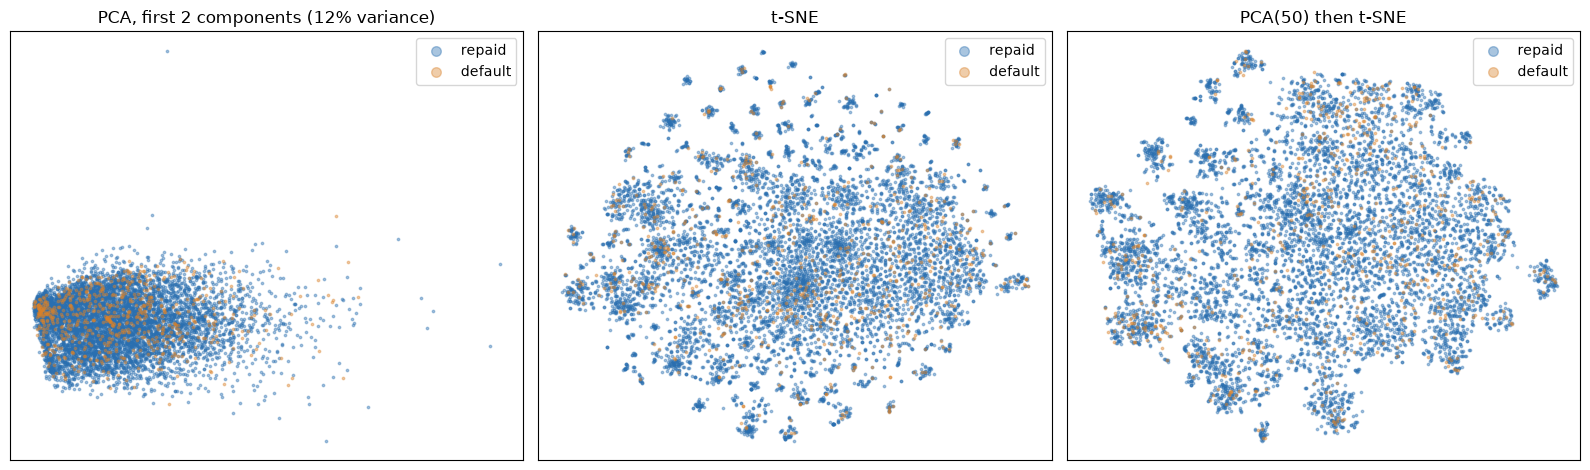

In [24]:
def scatter(ax, P, labels, title, palette, names):
    for lab, col in palette.items():
        m = labels == lab
        ax.scatter(P[m, 0], P[m, 1], s=3, alpha=0.4, c=col, label=names[lab], rasterized=True)
    ax.set_title(title); ax.legend(markerscale=4, loc="best")

cls_pal, cls_names = {0: "#2a6fb0", 1: "#d9822b"}, {0: "repaid", 1: "default"}
pcs = Z[sub, :2]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
scatter(ax[0], pcs, ysub, f"PCA, first 2 components ({evr[:2].sum():.0%} variance)", cls_pal, cls_names)
scatter(ax[1], tsne_raw, ysub, "t-SNE", cls_pal, cls_names)
scatter(ax[2], tsne_pca, ysub, "PCA(50) then t-SNE", cls_pal, cls_names)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(OUT / "figure2.png", dpi=150); plt.show()

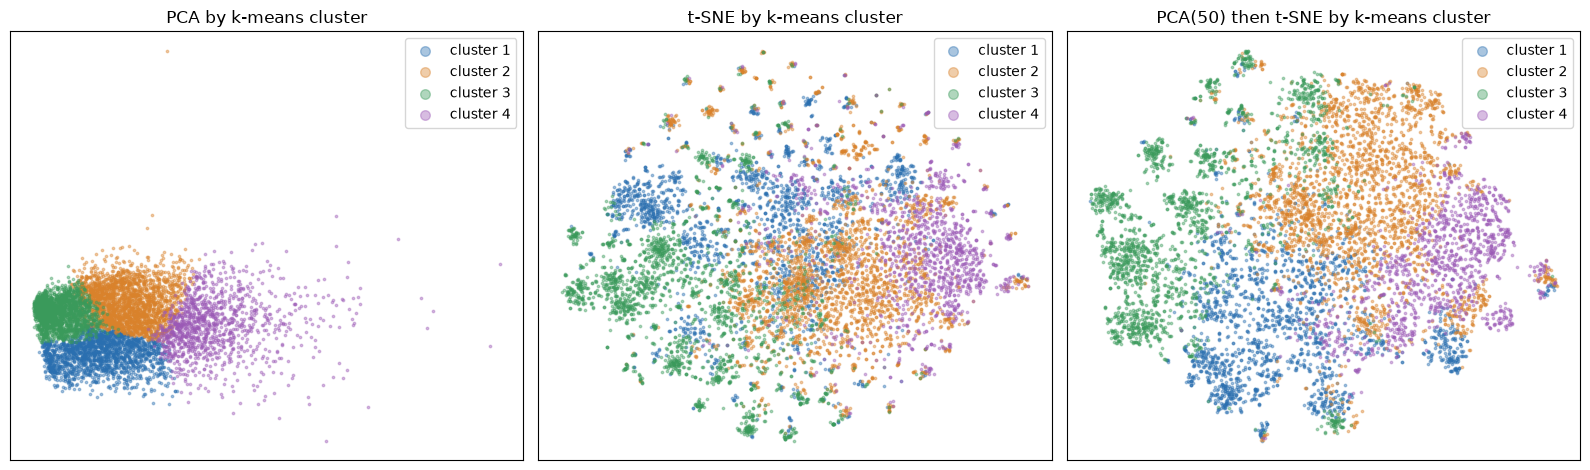

In [25]:
# same embeddings coloured by k-means cluster, to check for the four visible clusters
cl_pal = dict(zip(range(K), ["#2a6fb0", "#d9822b", "#3a9a5b", "#9b59b6"]))
cl_names = {c: f"cluster {c + 1}" for c in range(K)}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, P, t in zip(ax, (pcs, tsne_raw, tsne_pca), ("PCA", "t-SNE", "PCA(50) then t-SNE")):
    scatter(a, P, csub, t + " by k-means cluster", cl_pal, cl_names); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(OUT / "figure2_clusters.png", dpi=150); plt.show()

**Findings.** PC1+PC2 explain 12.3% of the variance (paper: about 23%); 50 components explain 47.6%. Our feature set is larger and mostly un-correlated aggregates (702 columns after encoding vs the paper's 651), which spreads variance over more directions. The classes overlap almost completely in all three views, matching the paper's main qualitative finding. The PCA plane shows one dense blob with a long tail, and the k-means clusters appear as adjacent slices of it rather than four separated groups; t-SNE shows many small local clumps but no four-way split. So we do not see the four distinct clusters the paper describes.

## Notes on differences from the paper

- **Features:** 832 joined columns, 702 after the 30% missing-value drop and encoding (paper: 217 raw, 651 after). Credit-card aggregates are almost all dropped by the 30% rule because only about a third of clients have card history; only `cc_COUNT` survives (counts of records are set to 0 for clients with no history).
- **Missing values:** mean imputation keeps all 307,511 rows; the paper's row dropping keeps 46.5% of rows here (paper: 33%). LightGBM AUC is 0.781 with imputation against 0.775 after dropping rows, so imputation costs nothing and keeps more data.
- **Balancing:** down-sampling, SMOTE and class weights give about the same AUC (0.776 to 0.781). Accuracy depends mostly on the test ratio: 0.92 at the natural ratio with no balancing, about 0.71 with down-sampling or class weights; SMOTE behaves like no balancing. Both test views are reported.
- **Clustering:** silhouette is highest at k=2 and the elbow is flat, so k=4 is not reproduced as best. Per-cluster accuracy is 0.68 to 0.72, without the paper's 82% cluster.
- **Table IV:** positive-class precision 1.00 is not reproduced (0.12 to 0.19 natural, 0.68 to 0.72 balanced); see section 7.
- **PCA:** 12% rather than 23% variance in two components.
- **Polynomial features:** top-20 degree-2 terms add only +0.002 AUC to logistic regression.